Koefisien Korelasi Pearson: 0.9845
P-Value: 3.3491e-40


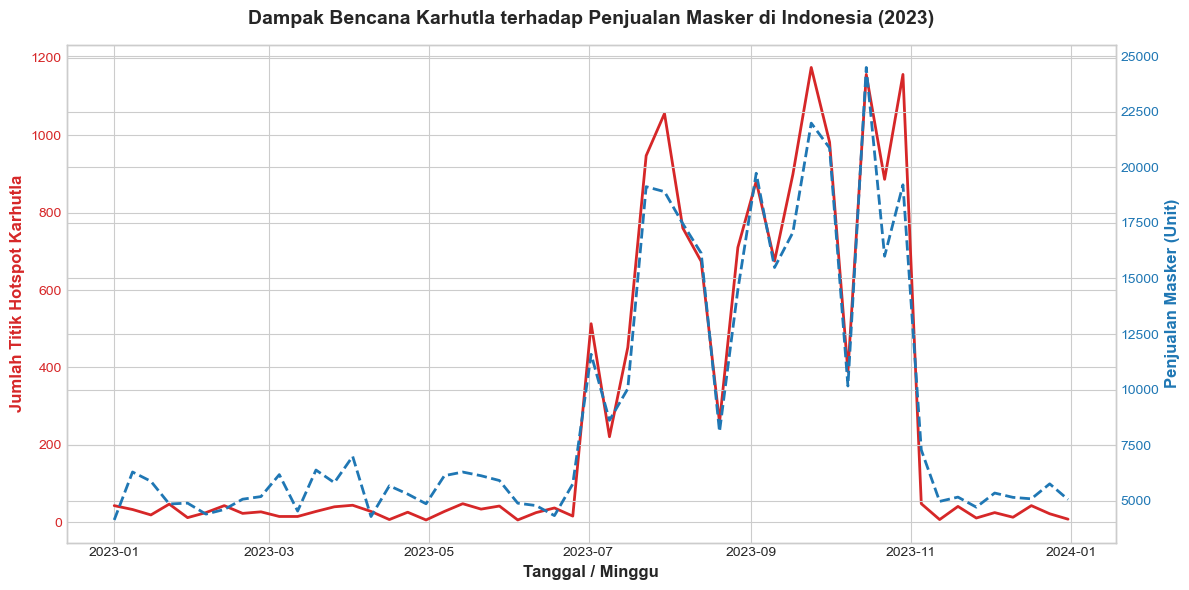

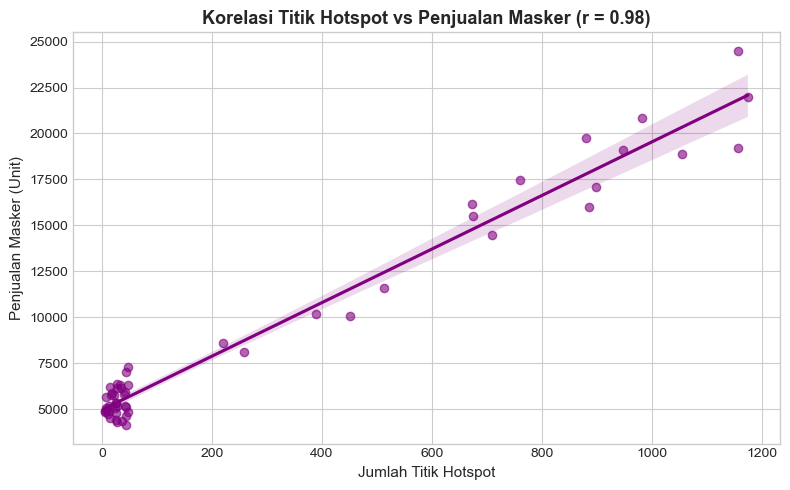

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

# Set style visualisasi
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")

# 1. SIMULASI DATASET (Dapat diganti dengan data asli jika ada)
np.random.seed(42)
dates = pd.date_range(start="2023-01-01", end="2023-12-31", freq="W")

# Jumlah Hotspot (Musim kemarau/Karhutla memuncak di Jul-Okt)
hotspots = [np.random.randint(5, 50) if m not in [7,8,9,10] 
            else np.random.randint(200, 1200) for m in dates.month]

# Penjualan Masker (Berbanding lurus dengan hotspot + random noise)
mask_sales = [int(h * np.random.uniform(12, 18) + np.random.normal(5000, 800)) for h in hotspots]

df = pd.DataFrame({
    'Date': dates,
    'Hotspot_Count': hotspots,
    'Mask_Sales_Units': mask_sales
})

# 2. ANALISIS KORELASI
corr_coef, p_value = pearsonr(df['Hotspot_Count'], df['Mask_Sales_Units'])
print(f"Koefisien Korelasi Pearson: {corr_coef:.4f}")
print(f"P-Value: {p_value:.4e}")

# 3. VISUALISAI 1: Dual-Axis Trend Line (Hotspot vs Penjualan Masker)
fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:red'
ax1.set_xlabel('Tanggal / Minggu', fontsize=12, fontweight='bold')
ax1.set_ylabel('Jumlah Titik Hotspot Karhutla', color=color, fontsize=12, fontweight='bold')
ax1.plot(df['Date'], df['Hotspot_Count'], color=color, linewidth=2, label='Hotspot Karhutla')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  
color = 'tab:blue'
ax2.set_ylabel('Penjualan Masker (Unit)', color=color, fontsize=12, fontweight='bold')
ax2.plot(df['Date'], df['Mask_Sales_Units'], color=color, linewidth=2, linestyle='--', label='Penjualan Masker')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Dampak Bencana Karhutla terhadap Penjualan Masker di Indonesia (2023)', fontsize=14, pad=15, fontweight='bold')
fig.tight_layout()
plt.savefig('../assets/sales_vs_hotspots.png', dpi=300)
plt.show()

# 4. VISUALISASI 2: Scatter Plot dengan Regression Line
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x='Hotspot_Count', y='Mask_Sales_Units', color='purple', scatter_kws={'alpha':0.6})
plt.title(f'Korelasi Titik Hotspot vs Penjualan Masker (r = {corr_coef:.2f})', fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Titik Hotspot', fontsize=11)
plt.ylabel('Penjualan Masker (Unit)', fontsize=11)
plt.tight_layout()
plt.savefig('../assets/correlation_matrix.png', dpi=300)
plt.show()